# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Rakha Makarim | 5054251010 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **PyTorch** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Set random seed dengan torch.manual_seed(42) dan np.random.seed(42).
# Tentukan device: device = "cuda" if torch.cuda.is_available() else "cpu", lalu tampilkan device yang digunakan.

import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)
sns.set_theme(style="whitegrid")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")


Device: NVIDIA GeForce RTX 4050 Laptop GPU


In [2]:
# Load file fashion-mnist_train.csv dan fashion-mnist_test.csv.
# Setiap baris berisi 1 kolom label dan 784 kolom piksel (28×28) bernilai 0-255.
# Tampilkan ukuran data train dan test.

cands = [Path("../Data/Fashion/fashion-mnist_train.csv"),
         Path("Data/Fashion/fashion-mnist_train.csv"),
         Path("Deep Learning/Data/Fashion/fashion-mnist_train.csv")]
train_csv = next((p for p in cands if p.exists()), None)
if train_csv is None:
    raise FileNotFoundError("fashion-mnist_train.csv tidak ditemukan")
test_csv = train_csv.parent / "fashion-mnist_test.csv"

df_train = pd.read_csv(train_csv)
df_test = pd.read_csv(test_csv)
print("Train:", df_train.shape, "| Test:", df_test.shape)
print(df_train.head().iloc[:, :6].to_string(index=False))


Train: (60000, 785) | Test: (10000, 785)
 label  pixel1  pixel2  pixel3  pixel4  pixel5
     2       0       0       0       0       0
     9       0       0       0       0       0
     6       0       0       0       0       0
     0       0       0       0       1       2
     3       0       0       0       0       0


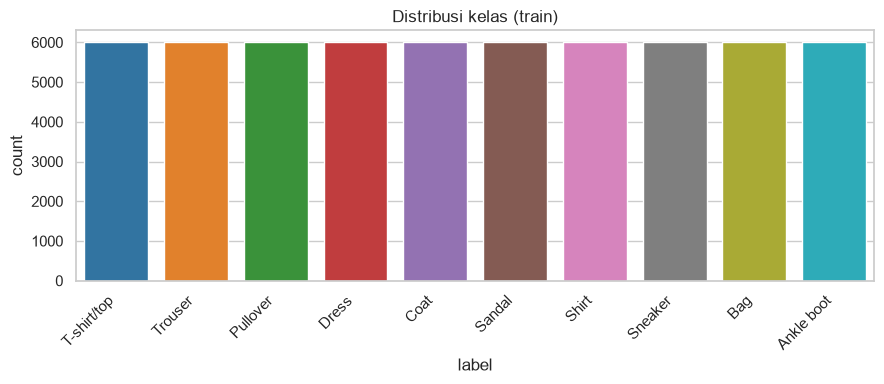

In [3]:
# Buat list atau dictionary yang memetakan label angka (0-9) ke nama kelas.
# Tampilkan distribusi kelas pada train set dalam bentuk bar plot.

LABELS = {0: "T-shirt/top", 1: "Trouser", 2: "Pullover", 3: "Dress", 4: "Coat",
          5: "Sandal", 6: "Shirt", 7: "Sneaker", 8: "Bag", 9: "Ankle boot"}

plt.figure(figsize=(9, 4))
sns.countplot(x=df_train["label"], hue=df_train["label"], palette="tab10", legend=False)
plt.title("Distribusi kelas (train)")
plt.xticks(range(10), [LABELS[i] for i in range(10)], rotation=45, ha="right")
plt.tight_layout()
plt.show()


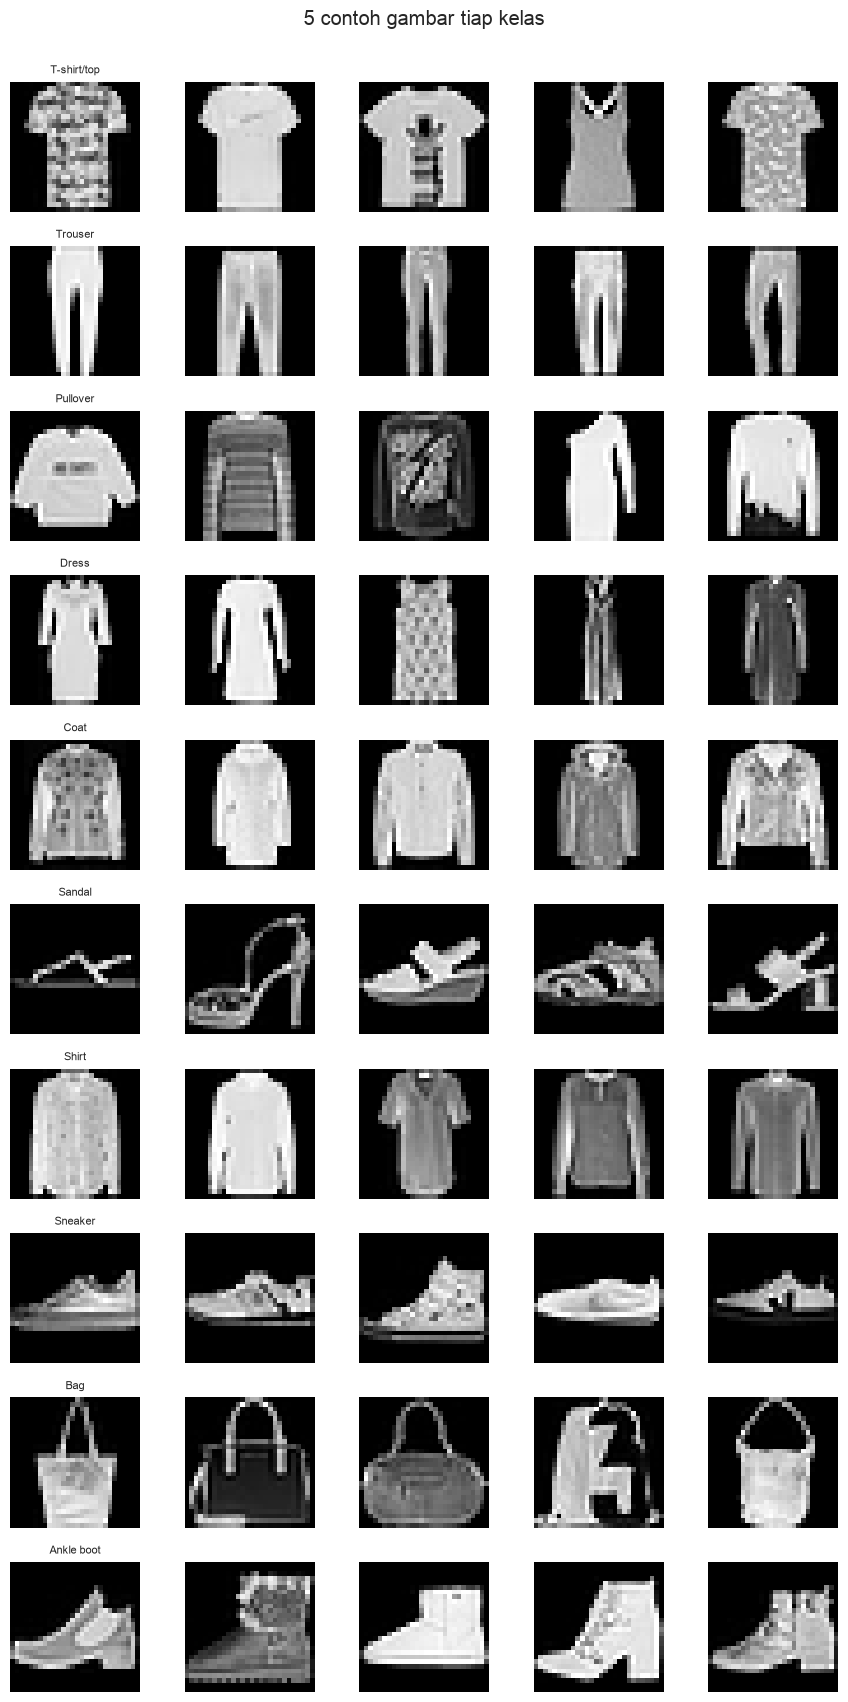

In [4]:
# Tampilkan contoh gambar dari setiap kelas (misalnya grid 10 kelas × 5 gambar) beserta nama kelasnya.
# Kelas mana saja yang secara visual terlihat mirip?

fig, axes = plt.subplots(10, 5, figsize=(9, 17))
for c in range(10):
    imgs = df_train[df_train["label"] == c].iloc[:5, 1:].values.reshape(-1, 28, 28)
    for j, img in enumerate(imgs):
        axes[c, j].imshow(img, cmap="gray")
        axes[c, j].axis("off")
        if j == 0:
            axes[c, j].set_title(LABELS[c], fontsize=8)
plt.suptitle("5 contoh gambar tiap kelas", y=1.0)
plt.tight_layout()
plt.show()


## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

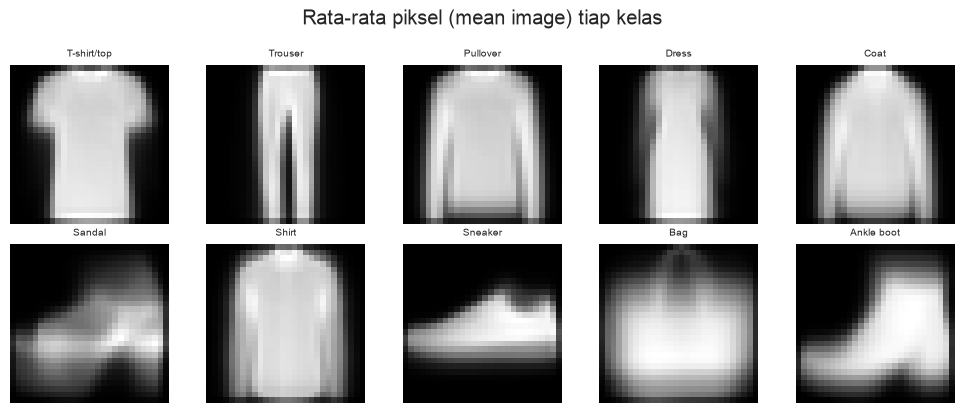

In [5]:
# Mean image tiap kelas: pola rata-rata yang dipelajari tiap kelas
fig, axes = plt.subplots(2, 5, figsize=(10, 4.2))
for c, ax in zip(range(10), axes.flat):
    img = df_train[df_train["label"] == c].iloc[:, 1:].mean(axis=0).values.reshape(28, 28)
    ax.imshow(img, cmap="gray")
    ax.set_title(LABELS[c], fontsize=7)
    ax.axis("off")
plt.suptitle("Rata-rata piksel (mean image) tiap kelas")
plt.tight_layout()
plt.show()


# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di PyTorch, urutan dimensi gambar adalah **(batch, channel, tinggi, lebar)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)`, atau `(N, 1, 28, 28)` dengan `nn.Flatten()` di awal model |
| CNN | `(N, 1, 28, 28)` |

In [6]:
# Pisahkan label (y) dan piksel (X) untuk data train dan test.

X_train = df_train.iloc[:, 1:].values
y_train = df_train["label"].values.astype(int)
X_test = df_test.iloc[:, 1:].values
y_test = df_test["label"].values.astype(int)

print("Train:", X_train.shape, y_train.shape)
print("Test :", X_test.shape, y_test.shape)


Train: (60000, 784) (60000,)
Test : (10000, 784) (10000,)


In [7]:
# Normalisasi nilai piksel ke rentang 0-1 (bagi dengan 255).

X_train = X_train / 255.0
X_test = X_test / 255.0
print("Rentang piksel:", X_train.min(), "-", X_train.max())


Rentang piksel: 0.0 - 1.0


In [8]:
# Bagi data train menjadi train set dan validation set (misalnya 90:10) dengan stratify=y.
# Test set dari file fashion-mnist_test.csv hanya digunakan untuk evaluasi akhir.

X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.1,
                                            stratify=y_train, random_state=42)
print("train:", len(X_tr), "| val:", len(X_val), "| test:", len(X_test))


train: 54000 | val: 6000 | test: 10000


In [9]:
# Ubah data menjadi tensor: X bertipe torch.float32 dengan bentuk (N, 1, 28, 28), y bertipe torch.long (wajib untuk nn.CrossEntropyLoss).
# Buat DataLoader untuk train, validation, dan test menggunakan TensorDataset (shuffle=True hanya untuk train).

BATCH = 128

def make_dl(X, y, shuffle=False):
    ds = TensorDataset(torch.tensor(X, dtype=torch.float32).view(-1, 1, 28, 28),
                       torch.tensor(y, dtype=torch.long))
    return DataLoader(ds, batch_size=BATCH, shuffle=shuffle)

train_dl = make_dl(X_tr, y_tr, shuffle=True)
val_dl = make_dl(X_val, y_val)
test_dl = make_dl(X_test, y_test)
print("Batch train/val/test:", len(train_dl), len(val_dl), len(test_dl))


Batch train/val/test: 422 47 79


# 3. Eksperimen Model

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output** tanpa Softmax dan **`nn.CrossEntropyLoss`** sebagai loss function. Loss ini sudah menyertakan Softmax di dalamnya.

Contoh arsitektur: `Flatten → Linear(784, 256) → ReLU → Linear(256, 128) → ReLU → Linear(128, 10)`

In [10]:
# Definisikan arsitektur ANN sebagai class turunan nn.Module, lalu pindahkan ke device dengan model.to(device).
# Tampilkan arsitektur model dengan print(model) dan jumlah parameternya: sum(p.numel() for p in model.parameters()).

class FashANN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.net(x)

ann = FashANN().to(DEVICE)
print(ann)
print("Jumlah parameter:", sum(p.numel() for p in ann.parameters()))


FashANN(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 235146


In [11]:
# Tentukan loss function (nn.CrossEntropyLoss), optimizer, learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Setiap batch harus dipindahkan ke device yang sama dengan model (x.to(device), y.to(device)).
# Di akhir setiap epoch, hitung loss dan accuracy train dan validation (gunakan model.eval() dan torch.no_grad()), simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.2 dan 3.3.

EPOCHS, LR = 10, 1e-3

def train_model(model, train_dl, val_dl, epochs=EPOCHS, lr=LR):
    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for ep in range(epochs):
        model.train()
        running = correct = tot = 0
        for xb, yb in train_dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            logits = model(xb)
            loss = criterion(logits, yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            running += loss.item() * len(xb)
            correct += (logits.argmax(1) == yb).sum().item()
            tot += len(xb)
        history["train_loss"].append(running / tot)
        history["train_acc"].append(correct / tot)

        model.eval()
        running = correct = tot = 0
        with torch.no_grad():
            for xb, yb in val_dl:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                logits = model(xb)
                running += criterion(logits, yb).item() * len(xb)
                correct += (logits.argmax(1) == yb).sum().item()
                tot += len(xb)
        history["val_loss"].append(running / tot)
        history["val_acc"].append(correct / tot)

        print(f"epoch {ep + 1}/{epochs} | train loss {history['train_loss'][-1]:.4f} "
              f"acc {history['train_acc'][-1]:.4f} | val loss {history['val_loss'][-1]:.4f} "
              f"acc {history['val_acc'][-1]:.4f}")
    return history

history_ann = train_model(ann, train_dl, val_dl)


epoch 1/10 | train loss 0.5862 acc 0.7934 | val loss 0.4435 acc 0.8400


epoch 2/10 | train loss 0.4019 acc 0.8540 | val loss 0.3772 acc 0.8662


epoch 3/10 | train loss 0.3541 acc 0.8714 | val loss 0.3532 acc 0.8725


epoch 4/10 | train loss 0.3272 acc 0.8818 | val loss 0.3464 acc 0.8743


epoch 5/10 | train loss 0.3092 acc 0.8861 | val loss 0.3438 acc 0.8730


epoch 6/10 | train loss 0.2902 acc 0.8924 | val loss 0.3310 acc 0.8790


epoch 7/10 | train loss 0.2768 acc 0.8983 | val loss 0.3254 acc 0.8782


epoch 8/10 | train loss 0.2662 acc 0.9008 | val loss 0.3628 acc 0.8670


epoch 9/10 | train loss 0.2563 acc 0.9040 | val loss 0.3282 acc 0.8808


epoch 10/10 | train loss 0.2447 acc 0.9083 | val loss 0.3192 acc 0.8822


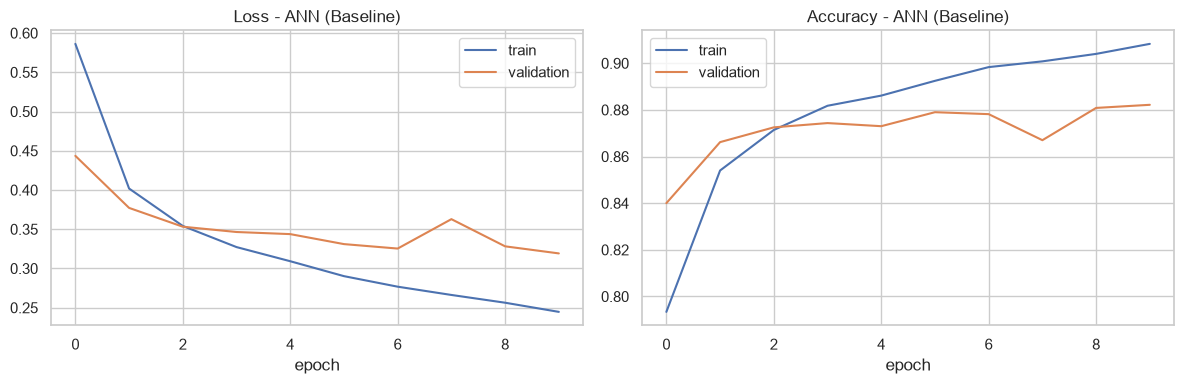

In [12]:
# Tampilkan learning curve (loss dan accuracy) train vs validation.

def plot_history(history, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["train_loss"], label="train")
    axes[0].plot(history["val_loss"], label="validation")
    axes[0].set_title(f"Loss - {title}")
    axes[0].set_xlabel("epoch")
    axes[0].legend()
    axes[1].plot(history["train_acc"], label="train")
    axes[1].plot(history["val_acc"], label="validation")
    axes[1].set_title(f"Accuracy - {title}")
    axes[1].set_xlabel("epoch")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_history(history_ann, "ANN (Baseline)")


In [13]:
# Lakukan prediksi pada test set dengan model.eval() dan torch.no_grad().
# Ambil kelas dengan nilai output terbesar menggunakan argmax(dim=1). Simpan hasil prediksi label dalam bentuk numpy array.

def predict(model, dl):
    model.eval()
    preds = []
    with torch.no_grad():
        for xb, _ in dl:
            preds.append(model(xb.to(DEVICE)).argmax(1).cpu().numpy())
    return np.concatenate(preds)

y_pred_ann = predict(ann, test_dl)
print("ANN - test accuracy:", round(accuracy_score(y_test, y_pred_ann), 4))


ANN - test accuracy: 0.8907


## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2d → ReLU → MaxPool2d, lalu dilanjutkan Flatten dan Linear.

Contoh arsitektur: `[Conv2d(1, 32, 3, padding=1) → ReLU → MaxPool2d(2)] → [Conv2d(32, 64, 3, padding=1) → ReLU → MaxPool2d(2)] → Flatten → Linear(64×7×7, 128) → ReLU → Linear(128, 10)`

In [14]:
# Definisikan arsitektur CNN sederhana sebagai class turunan nn.Module (gunakan nn.Conv2d, nn.MaxPool2d, nn.Flatten, dan nn.Linear).
# Tampilkan arsitektur model beserta jumlah parameternya.
# Hitung secara manual ukuran output setiap layer konvolusi dan pooling menggunakan rumus (W - K + 2P) / S + 1.
# Hasil perhitungan ini menentukan ukuran input nn.Linear pertama setelah Flatten (channel × tinggi × lebar).
# Cocokkan dengan mengirim satu tensor dummy torch.zeros(1, 1, 28, 28) ke bagian konvolusi dan cetak bentuk outputnya.

class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        # Conv1: (28-3+2*1)/1+1 = 28 -> Pool: 28/2 = 14
        # Conv2: (14-3+2*1)/1+1 = 14 -> Pool: 14/2 = 7
        # Flatten: 64 * 7 * 7 = 3136
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model_cnn = SimpleCNN().to(DEVICE)
print(model_cnn)
print("Jumlah parameter:", sum(p.numel() for p in model_cnn.parameters()))

dummy = torch.zeros(1, 1, 28, 28, device=DEVICE)
print("Bentuk output bagian konvolusi untuk input (1,1,28,28):",
      tuple(model_cnn.features(dummy).shape))


SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 421642


Bentuk output bagian konvolusi untuk input (1,1,28,28): (1, 64, 7, 7)


epoch 1/10 | train loss 0.5333 acc 0.8103 | val loss 0.4007 acc 0.8528


epoch 2/10 | train loss 0.3334 acc 0.8805 | val loss 0.3304 acc 0.8797


epoch 3/10 | train loss 0.2857 acc 0.8968 | val loss 0.3008 acc 0.8915


epoch 4/10 | train loss 0.2549 acc 0.9069 | val loss 0.2556 acc 0.9065


epoch 5/10 | train loss 0.2291 acc 0.9170 | val loss 0.2416 acc 0.9140


epoch 6/10 | train loss 0.2094 acc 0.9242 | val loss 0.2444 acc 0.9083


epoch 7/10 | train loss 0.1952 acc 0.9278 | val loss 0.2294 acc 0.9142


epoch 8/10 | train loss 0.1766 acc 0.9355 | val loss 0.2273 acc 0.9163


epoch 9/10 | train loss 0.1615 acc 0.9419 | val loss 0.2179 acc 0.9227


epoch 10/10 | train loss 0.1467 acc 0.9470 | val loss 0.2245 acc 0.9198


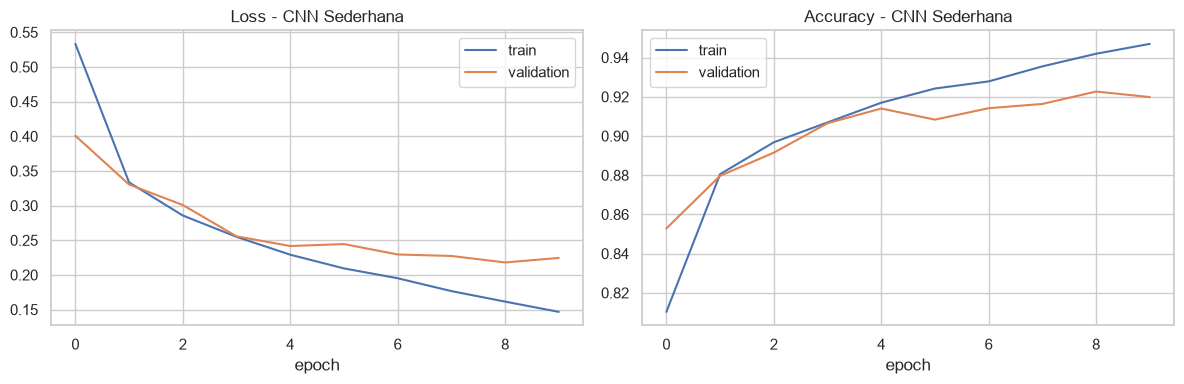

In [15]:
# Latih model dengan pengaturan yang sama seperti 3.1 agar perbandingan adil.
# Tampilkan learning curve train vs validation.

history_cnn = train_model(model_cnn, train_dl, val_dl)
plot_history(history_cnn, "CNN Sederhana")


In [16]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.

y_pred_cnn = predict(model_cnn, test_dl)
print("CNN Sederhana - test accuracy:", round(accuracy_score(y_test, y_pred_cnn), 4))


CNN Sederhana - test accuracy: 0.9229


## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [17]:
# Definisikan arsitektur CNN dengan Batch Normalization dan Dropout.
# Urutan yang umum: nn.Conv2d -> nn.BatchNorm2d(jumlah_channel_output) -> nn.ReLU -> nn.MaxPool2d.
# Tambahkan nn.Dropout(p) sebelum layer output.
# Ingat: BatchNorm dan Dropout berperilaku berbeda saat training dan evaluasi, pastikan memanggil model.train() dan model.eval() di tempat yang tepat.
# Tampilkan arsitektur model beserta jumlah parameternya.

class CNNBN(nn.Module):
    def __init__(self, p=0.25):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
            nn.Dropout(p), nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model_bn = CNNBN().to(DEVICE)
print(model_bn)
print("Jumlah parameter:", sum(p.numel() for p in model_bn.parameters()))


CNNBN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 421834


epoch 1/10 | train loss 0.4514 acc 0.8376 | val loss 0.3271 acc 0.8817


epoch 2/10 | train loss 0.3009 acc 0.8908 | val loss 0.2781 acc 0.8987


epoch 3/10 | train loss 0.2617 acc 0.9043 | val loss 0.2723 acc 0.9007


epoch 4/10 | train loss 0.2370 acc 0.9135 | val loss 0.2469 acc 0.9100


epoch 5/10 | train loss 0.2206 acc 0.9184 | val loss 0.2273 acc 0.9193


epoch 6/10 | train loss 0.2000 acc 0.9270 | val loss 0.2332 acc 0.9150


epoch 7/10 | train loss 0.1858 acc 0.9308 | val loss 0.2381 acc 0.9115


epoch 8/10 | train loss 0.1682 acc 0.9365 | val loss 0.2207 acc 0.9225


epoch 9/10 | train loss 0.1589 acc 0.9403 | val loss 0.2376 acc 0.9148


epoch 10/10 | train loss 0.1474 acc 0.9449 | val loss 0.2243 acc 0.9227


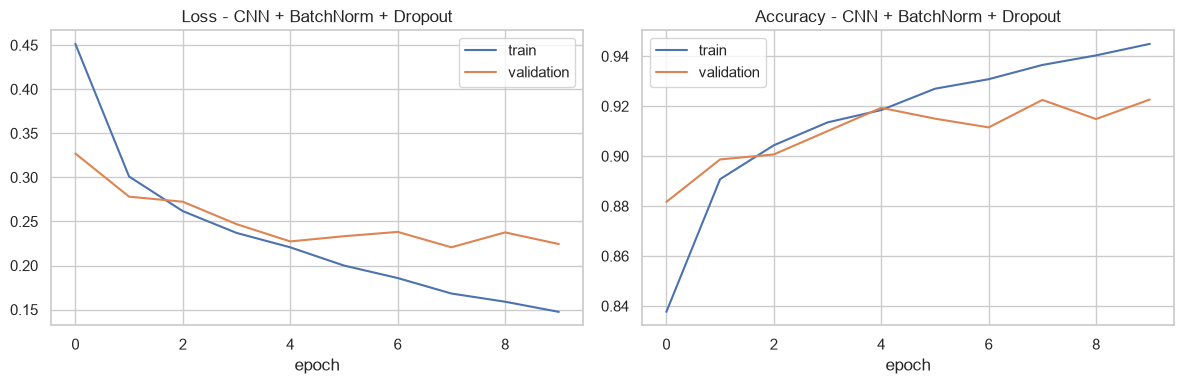

In [18]:
# Latih model dengan pengaturan yang sama seperti 3.2.
# Tampilkan learning curve train vs validation.
# Perhatikan selisih antara train dan validation dibandingkan dengan model 3.2.

history_bn = train_model(model_bn, train_dl, val_dl)
plot_history(history_bn, "CNN + BatchNorm + Dropout")


In [19]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.

y_pred_bn = predict(model_bn, test_dl)
print("CNN + BN + Dropout - test accuracy:", round(accuracy_score(y_test, y_pred_bn), 4))


CNN + BN + Dropout - test accuracy: 0.9286


# 4. Evaluasi Model

In [20]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score (macro average),
# beserta jumlah parameter setiap model. Sajikan dalam satu tabel perbandingan.

preds = {"ANN": y_pred_ann, "CNN Sederhana": y_pred_cnn, "CNN + BN + Dropout": y_pred_bn}
model_objs = {"ANN": ann, "CNN Sederhana": model_cnn, "CNN + BN + Dropout": model_bn}

rows = []
for name, pred in preds.items():
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred, average="macro"),
                 "Recall": recall_score(y_test, pred, average="macro"),
                 "F1-Score": f1_score(y_test, pred, average="macro"),
                 "Parameter": sum(p.numel() for p in model_objs[name].parameters())})
metrics_df = pd.DataFrame(rows).round(4)
print(metrics_df.to_string(index=False))


             Model  Accuracy  Precision  Recall  F1-Score  Parameter
               ANN    0.8907     0.8912  0.8907    0.8894     235146
     CNN Sederhana    0.9229     0.9245  0.9229    0.9233     421642
CNN + BN + Dropout    0.9286     0.9280  0.9286    0.9279     421834


In [21]:
# Tampilkan classification report (metrik per kelas) untuk model terbaik.

best_name = max(preds, key=lambda n: accuracy_score(y_test, preds[n]))
best_model = model_objs[best_name]
print("Model terbaik:", best_name)
print(classification_report(y_test, preds[best_name],
                            target_names=[LABELS[i] for i in range(10)]))


Model terbaik: CNN + BN + Dropout


              precision    recall  f1-score   support

 T-shirt/top       0.88      0.89      0.89      1000
     Trouser       0.98      0.99      0.99      1000
    Pullover       0.90      0.87      0.89      1000
       Dress       0.92      0.94      0.93      1000
        Coat       0.87      0.93      0.90      1000
      Sandal       0.98      0.98      0.98      1000
       Shirt       0.84      0.76      0.79      1000
     Sneaker       0.95      0.97      0.96      1000
         Bag       0.98      0.99      0.99      1000
  Ankle boot       0.98      0.96      0.97      1000

    accuracy                           0.93     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.93      0.93      0.93     10000



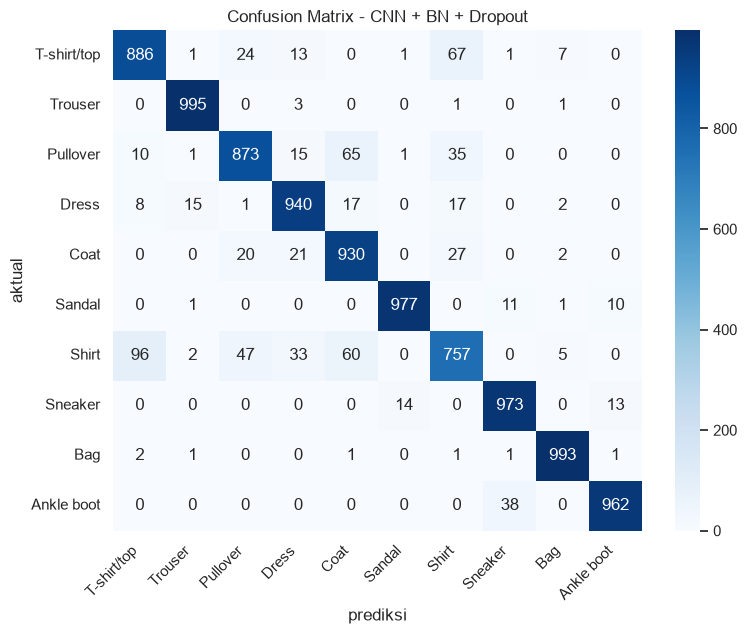

In [22]:
# Tampilkan Confusion Matrix 10×10 model terbaik dalam bentuk heatmap, gunakan nama kelas sebagai label sumbu.
# Pasangan kelas mana yang paling sering tertukar?

cm = confusion_matrix(y_test, preds[best_name])
plt.figure(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[LABELS[i] for i in range(10)],
            yticklabels=[LABELS[i] for i in range(10)])
plt.xlabel("prediksi")
plt.ylabel("aktual")
plt.title(f"Confusion Matrix - {best_name}")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


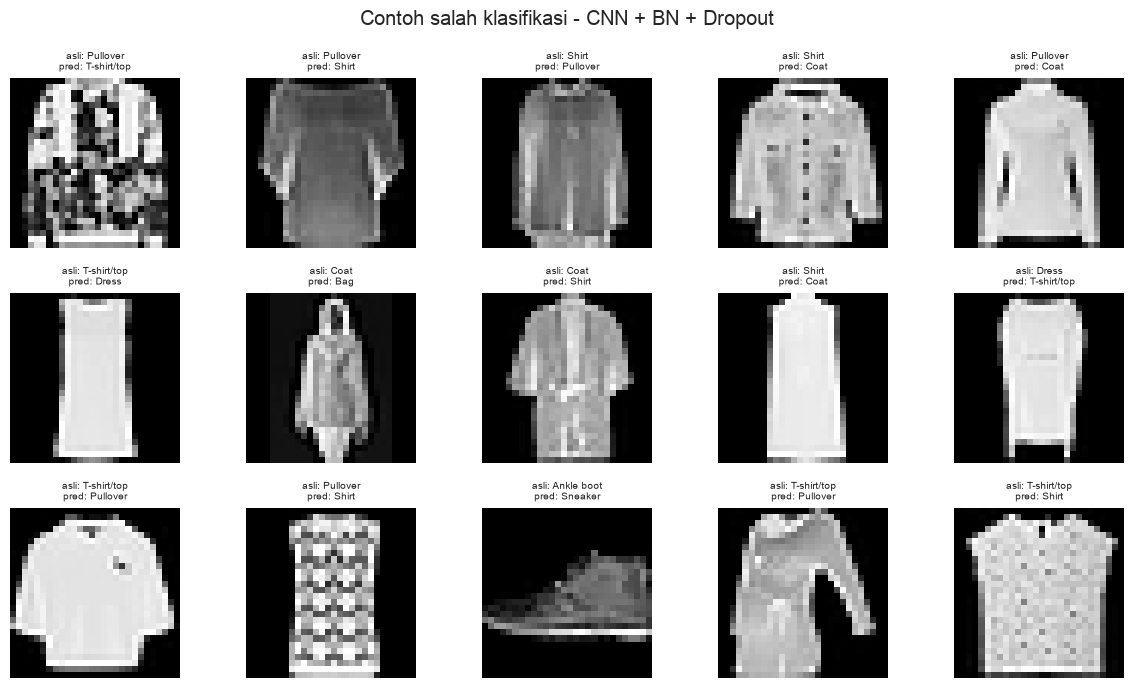

Jumlah salah klasifikasi pada test set: 714


In [23]:
# Tampilkan beberapa contoh gambar yang salah diklasifikasikan oleh model terbaik,
# beserta label asli dan label prediksinya.

y_best = preds[best_name]
wrong = np.where(y_best != y_test)[0][:15]

fig, axes = plt.subplots(3, 5, figsize=(12, 7))
for ax, i in zip(axes.flat, wrong):
    ax.imshow(X_test[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"asli: {LABELS[y_test[i]]}\npred: {LABELS[y_best[i]]}", fontsize=7)
    ax.axis("off")
for ax in axes.flat[len(wrong):]:
    ax.axis("off")
plt.suptitle(f"Contoh salah klasifikasi - {best_name}")
plt.tight_layout()
plt.show()
print("Jumlah salah klasifikasi pada test set:", int((y_best != y_test).sum()))


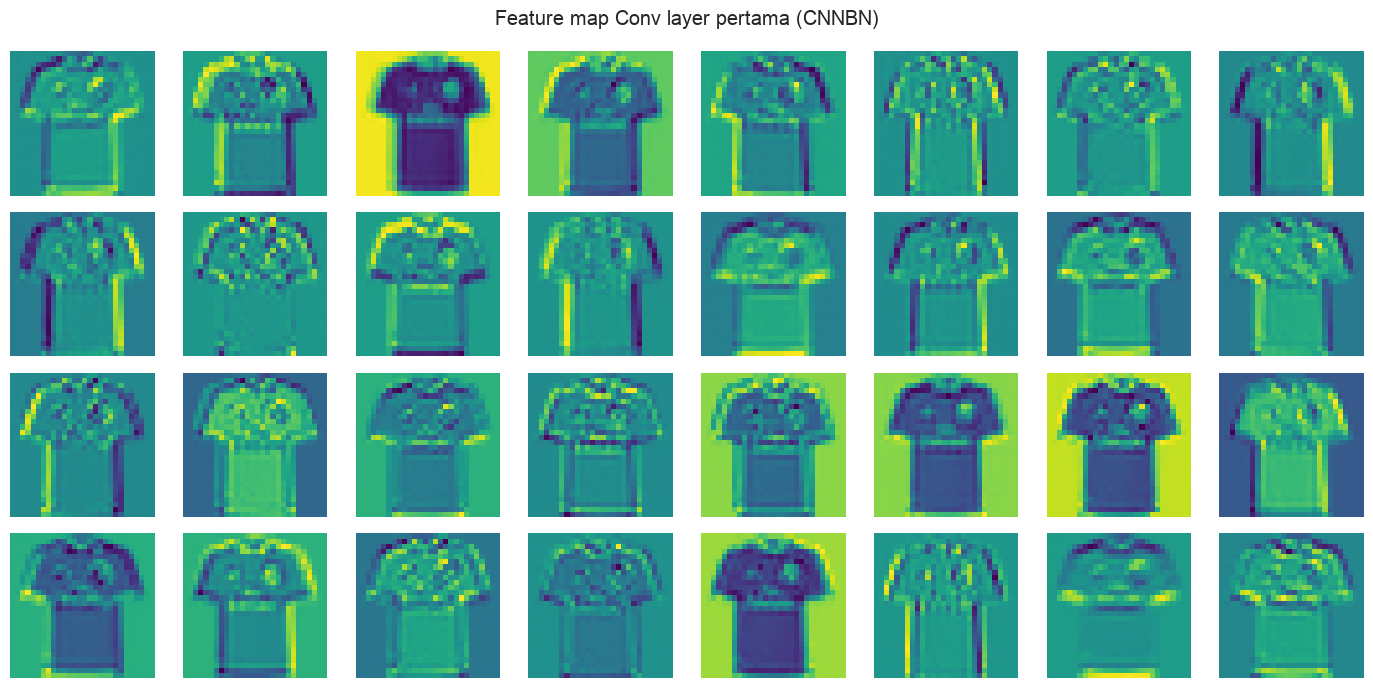

In [24]:
# Visualisasikan feature map dari layer konvolusi pertama model terbaik untuk satu gambar contoh.
# Kirim satu gambar (bentuk (1, 1, 28, 28)) ke layer konvolusi pertama saja, misalnya model.features[0](x) jika menggunakan nn.Sequential bernama features,
# lalu tampilkan setiap channel output-nya sebagai gambar (gunakan .detach().cpu().numpy()).
# Apa saja pola yang ditangkap oleh masing-masing filter?

conv_model = best_model if hasattr(best_model, "features") else model_bn

img = torch.tensor(X_test[0], dtype=torch.float32).view(1, 1, 28, 28).to(DEVICE)
with torch.no_grad():
    fmap = conv_model.features[0](img).squeeze().cpu().numpy()

fig, axes = plt.subplots(4, 8, figsize=(14, 7))
for ax, ch in zip(axes.flat, fmap):
    ax.imshow(ch, cmap="viridis")
    ax.axis("off")
plt.suptitle(f"Feature map Conv layer pertama ({conv_model.__class__.__name__})")
plt.tight_layout()
plt.show()


In [25]:
# Simpan bobot model terbaik dengan torch.save(model.state_dict(), "model.pth").
# Model ini akan digunakan kembali pada tugas Deployment, jadi simpan juga definisi class model kalian.

torch.save(best_model.state_dict(), "model.pth")
print(f"Model terbaik ({best_name}) disimpan ke model.pth")
print("Definisi class model ada pada cell arsitektur notebook ini (dibutuhkan untuk Deployment).")


Model terbaik (CNN + BN + Dropout) disimpan ke model.pth
Definisi class model ada pada cell arsitektur notebook ini (dibutuhkan untuk Deployment).


# 5. Analisis

Berdasarkan hasil eksperimen, model ANN, CNN sederhana, dan CNN dengan Batch Normalization serta Dropout menunjukkan perbedaan performa dalam melakukan klasifikasi gambar Fashion-MNIST. Model ANN digunakan sebagai baseline dengan mengubah gambar berukuran 28×28 piksel menjadi vektor berisi 784 nilai. Model ini memiliki 235.146 parameter dan menghasilkan accuracy sebesar 89,07% dengan F1-Score sebesar 0,8894. Meskipun mampu melakukan klasifikasi dengan cukup baik, proses flatten menyebabkan informasi mengenai posisi dan hubungan spasial antar piksel tidak dimanfaatkan secara langsung oleh model.

Penggunaan CNN sederhana meningkatkan accuracy menjadi 92,29% dan F1-Score menjadi 0,9233 dengan jumlah parameter sebanyak 421.642. Peningkatan ini menunjukkan bahwa convolutional layer lebih efektif dalam mengekstraksi karakteristik visual seperti tepi, bentuk, dan tekstur pakaian. Berbeda dengan ANN, CNN mempertahankan struktur spasial gambar selama proses ekstraksi fitur. Berdasarkan visualisasi feature map pada convolutional layer pertama, setiap filter menghasilkan respons yang berbeda terhadap bagian gambar, sehingga model dapat mempelajari berbagai pola visual yang membantu proses klasifikasi.

Pada eksperimen CNN dengan Batch Normalization dan Dropout, accuracy meningkat menjadi 92,86% dengan F1-Score sebesar 0,9279. Model ini memiliki 421.834 parameter, hanya bertambah 192 parameter dibandingkan CNN sederhana. Peningkatan performa tersebut menunjukkan bahwa penambahan Batch Normalization dan Dropout memberikan manfaat tanpa harus meningkatkan jumlah parameter secara signifikan. Batch Normalization membantu menstabilkan proses training, sedangkan Dropout digunakan untuk mengurangi ketergantungan model terhadap neuron tertentu.

Berdasarkan learning curve, ketiga model mengalami peningkatan training accuracy seiring bertambahnya epoch. Pada epoch terakhir, CNN sederhana memperoleh training accuracy sebesar 94,70% dan validation accuracy sebesar 91,98%. Sementara itu, CNN dengan Batch Normalization dan Dropout memperoleh training accuracy sebesar 94,49% dan validation accuracy sebesar 92,27%. Selisih accuracy antara training dan validation pada kedua model menunjukkan adanya indikasi overfitting, meskipun CNN dengan Batch Normalization dan Dropout memiliki selisih yang sedikit lebih kecil. Validation loss juga mengalami fluktuasi pada beberapa epoch, sehingga proses training masih dapat diperbaiki.

Berdasarkan Classification Report model terbaik, kategori Trouser dan Bag memperoleh F1-Score sebesar 0,99, sedangkan Shirt memiliki F1-Score terendah sebesar 0,79 dengan recall sebesar 0,76. Hasil ini menunjukkan bahwa model lebih mudah membedakan kategori dengan bentuk yang khas dibandingkan pakaian yang memiliki karakteristik visual serupa. Berdasarkan Confusion Matrix dan contoh kesalahan klasifikasi, kategori pakaian bagian atas seperti Shirt, T-shirt/top, dan Pullover masih sulit dibedakan karena memiliki bentuk yang relatif mirip pada gambar beresolusi rendah.

Secara keseluruhan, CNN dengan Batch Normalization dan Dropout memberikan performa terbaik dengan 9.286 prediksi benar dari 10.000 data testing. Hasil ini menunjukkan bahwa penggunaan convolutional layer lebih efektif dibandingkan ANN untuk klasifikasi gambar, sedangkan penambahan Batch Normalization dan Dropout dapat membantu meningkatkan kemampuan generalisasi model. Namun, peningkatan tersebut masih relatif kecil dan model masih mengalami kesulitan pada beberapa kategori dengan karakteristik visual yang serupa.

# 6. Kesimpulan dan Saran

Kesimpulan

Berdasarkan hasil eksperimen, model Convolutional Neural Network (CNN) memberikan performa yang lebih baik dibandingkan Artificial Neural Network (ANN) dalam klasifikasi gambar Fashion-MNIST. Model ANN memperoleh accuracy sebesar 89,07%, sedangkan CNN sederhana mencapai 92,29%. Performa terbaik diperoleh CNN dengan Batch Normalization dan Dropout dengan accuracy sebesar 92,86% dan F1-Score sebesar 0,9279.

Hasil tersebut menunjukkan bahwa penggunaan convolutional layer membantu model mengenali pola visual pada gambar dengan lebih baik. Penambahan Batch Normalization dan Dropout juga memberikan sedikit peningkatan performa dibandingkan CNN sederhana. Namun, beberapa kategori dengan bentuk yang mirip seperti Shirt, T-shirt/top, dan Pullover masih sulit dibedakan, sehingga kesalahan klasifikasi masih ditemukan.

Saran

Untuk eksperimen selanjutnya, dapat dilakukan hyperparameter tuning pada jumlah convolutional layer, ukuran kernel, learning rate, dan dropout rate. Penggunaan data augmentation juga dapat dicoba untuk meningkatkan kemampuan generalisasi model terhadap variasi gambar. Selain itu, eksperimen dengan arsitektur CNN yang lebih dalam dan penerapan Early Stopping dapat dilakukan untuk memperoleh performa yang lebih baik sekaligus mengurangi risiko overfitting. Evaluasi lebih lanjut juga perlu difokuskan pada kelas yang sering mengalami kesalahan klasifikasi, terutama kategori pakaian dengan karakteristik visual yang serupa.